# RV Curve Comparison

The following notebook provides a walkthrough on how to both use unspotable in jupyter and also demonstrates a comparison of the RV curves generated by the code

**NOTE:** to run this code, quad-limb-70i-units must already exist in the eridani-outputs folder.

## Library and Data Setup

### Core Imports

In [1]:
#General imports
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from cmcrameri import cm
import faulthandler
faulthandler.enable()

# Directory structure - this is required for running jupyter in a folder
from pathlib import Path
maindir = str(Path(os.getcwd()).parent)
libdir  = os.path.join(maindir, 'lib')
if not libdir in sys.path:
    sys.path.append(maindir)
    sys.path.append(libdir)

# lib imports
from lib import eigen
from lib import utils
from lib import fitclass as fc
from lib.spotable import spotable as se
from lib import lat_lon_lines

# import starry2 and set basic configuration
import starry2 as starry
starry.config.quiet = True
starry.config.lazy = True
sys.setrecursionlimit(10000) # starry seems to have a lot of recursion

### Importing each .py file

In [2]:
import create_eigens
import create_emaps
import create_rv
import create_real_null

### Reading Config File

In [3]:
fit = fc.Fit()
fit.read_config("../eridani.cfg")

cfg = fit.cfg

lmax = cfg.sim.lmax
udeg = cfg.star.udeg

# setting up units if present in cfg
if fit.cfg.star.units:
    scaler = 5.670374419e-8 * fit.cfg.star.teff**4
    power = int(np.floor(np.log10(scaler)))
    if power > 6:
        units = f"x10$^{power}$ W m$^{{-2}}$"
    else:
        units = f"W m$^{{-2}}$"
else:
    scaler = 1
    units = None

### Python magic commands for better notebook displays

In [4]:
%matplotlib inline

### Reading in data from quad-limb-70i-units

In [5]:
scaled_eigeny = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-eigeny.txt")

scaled_amps = np.loadtxt("../eridani-outputs/quad-limb-70i-units/stored-scaled-null-eigens/scaled-null-amps.txt")

ratio_no_limb = scaled_amps[0,0]

amps = scaled_amps[:,1]

In [6]:
print(f"Shape: {scaled_eigeny.shape} - {scaled_eigeny.shape[0]} maps with {scaled_eigeny.shape[1]} coefficients")
print(f"Shape: {scaled_amps.shape} - {scaled_amps.shape[0]} maps with {scaled_amps.shape[1]} coefficients (limb ratio & amp)")

Shape: (25, 36) - 25 maps with 36 coefficients
Shape: (25, 2) - 25 maps with 2 coefficients (limb ratio & amp)


### Setting up stars and star info

In [7]:
star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

uni_star = utils.initstar(fit, lmax, udeg=udeg, include_rv=True)

star.map[:,:] = scaled_eigeny[0]

star.map.amp = amps[0]

uni_star.map[0,0] = np.median(star.map.flux(theta=np.linspace(-180,180,91),rv=False).eval())

uni_star.map.amp /= ratio_no_limb
cbar_center = np.median(uni_star.map.render(projection="rect",rv=False).eval())
uni_star.map.amp *= ratio_no_limb

### Create output folder if it does not already exist

In [8]:
if not os.path.isdir("rv_curves_outputs"):
    os.mkdir("rv_curves_outputs")

## RV Curves #1

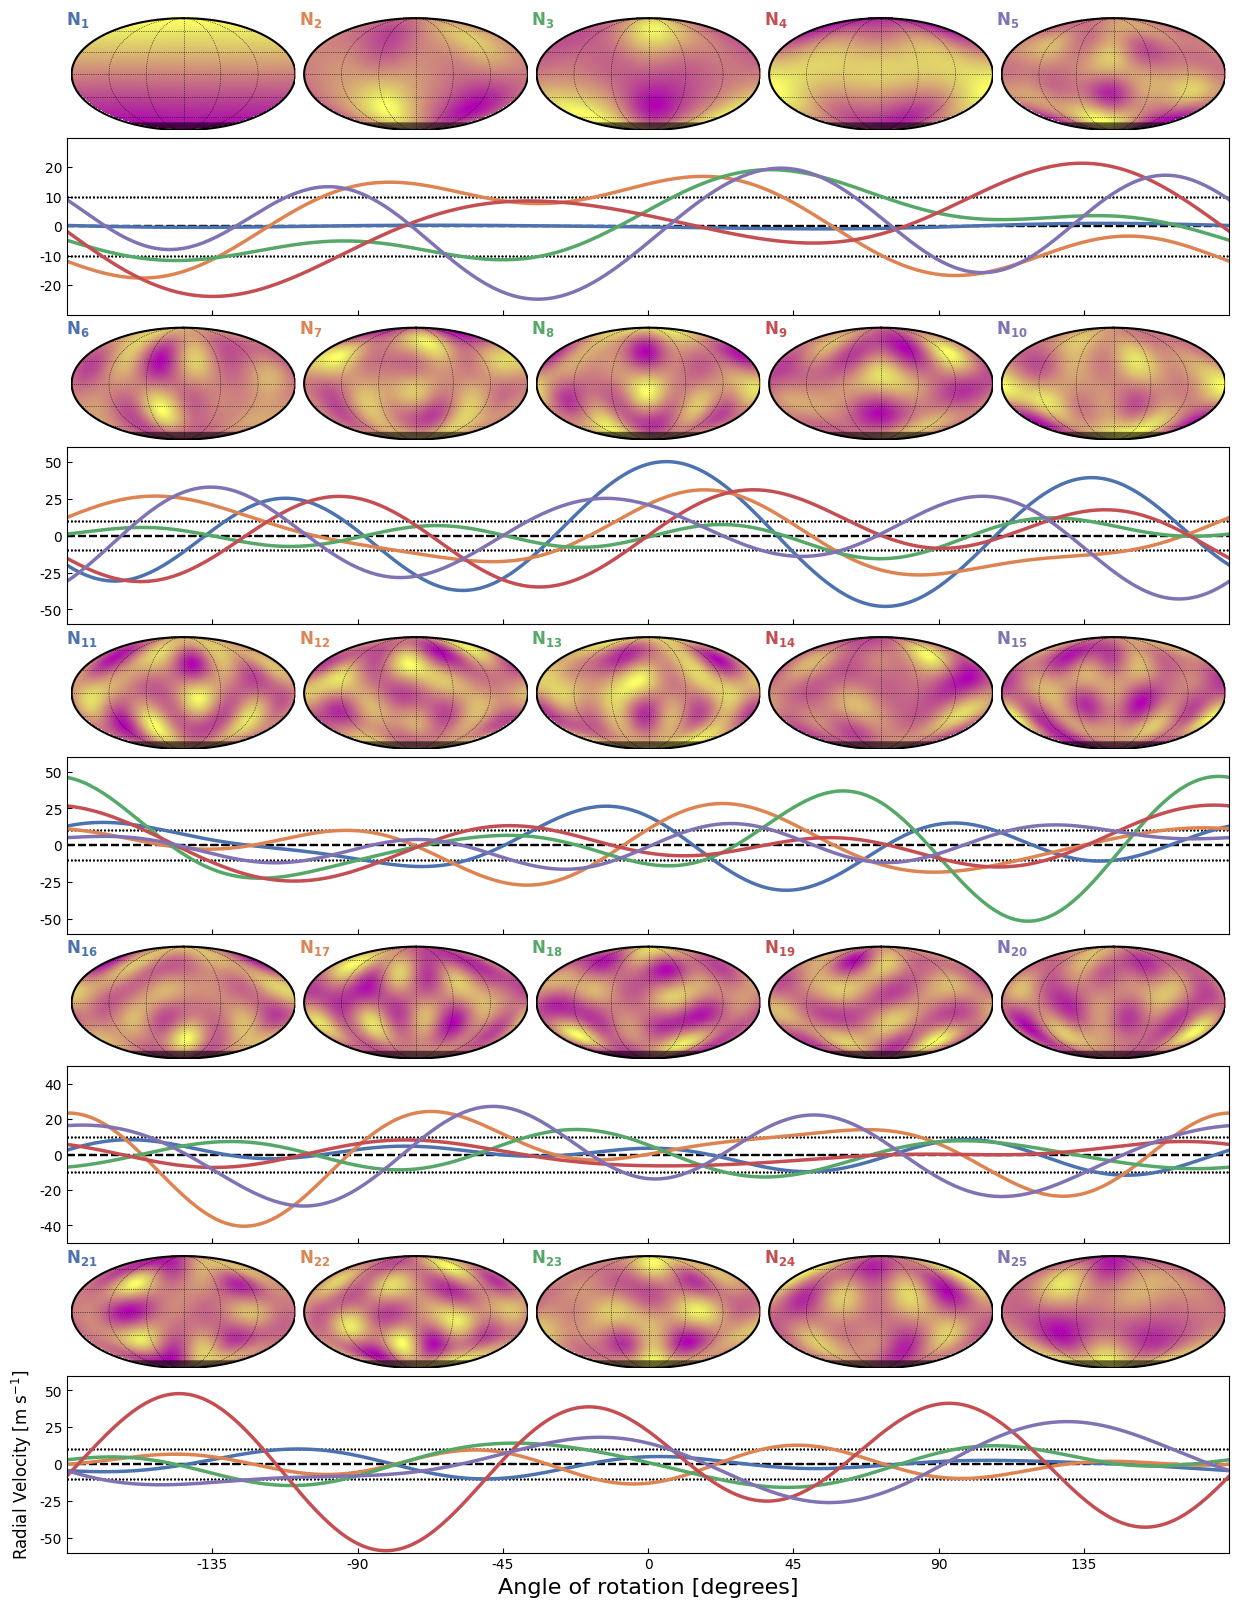

In [9]:
def rv_curves_one(star, y_coeffs, amps, ratio, theta = np.linspace(-180, 180, 361), fname = None,
                 transparent=False, labels=True, title = None, border=True, ticks=True, 
                 fontsize=16, colors=[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725), 
                                    (0.8666666666666667, 0.5176470588235295, 0.3215686274509804), 
                                    (0.3333333333333333, 0.6588235294117647, 0.40784313725490196), 
                                    (0.7686274509803922, 0.3058823529411765, 0.3215686274509804), 
                                    (0.5058823529411764, 0.4470588235294118, 0.7019607843137254), ], 
                 guidelines=True, cbar_center=None,
                 centerline=True, cline_color="k", dpi=300):
    

    fig = plt.figure(figsize=(15, 20))

    if cbar_center is None:
        gs = gridspec.GridSpec(10, 5, figure=fig,height_ratios=[1,1.5]*5)
    else:
        gs = gridspec.GridSpec(10, 6, figure=fig,height_ratios=[1,1.5]*5, width_ratios=[1]*5 + [0.05])

    image = star.map.render(theta=0,projection="moll",rv=False).eval()

    dx = 360.0 / image.shape[1] 
    dy = 180.0 / image.shape[0]

    if fname:
        extent = np.array([
            -180 - dx/2,  # Left
            180 - dx/2,       # Right
            -90 - dy/2,   # Bottom
            90 - dy/2         # Top
        ])
    else:
        extent = np.array([
            -180 - dx,  # Left
            180,      # Right
            -90 - dy,   # Bottom
            90 - dy/8         # Top
        ])

    k = 0
    for i in range(5):

        r = (i*2) + 1

        if cbar_center is None:
            c_ax = fig.add_subplot(gs[r, :])
        else:
            c_ax = fig.add_subplot(gs[r, :-1])

        max_rv = float("-inf")
        min_rv = float("inf")

        for j in range(5):
            star.map[:,:] = y_coeffs[k]

            star.map.amp = amps[k]

            rv_val = star.map.rv(theta=theta).eval()

            c_ax.plot(theta,rv_val,color=colors[j],zorder=2,lw=2.5)

            if centerline:
                c_ax.axhline(y=0,color=cline_color,linestyle="--",zorder=1,linewidth=1.5)

            if guidelines:
                c_ax.axhline(y=10,color=cline_color,linestyle=":",zorder=1,linewidth=1)
                c_ax.axhline(y=-10,color=cline_color,linestyle=":",zorder=1,linewidth=1)

            if np.max(rv_val) > max_rv:
                 max_rv = np.max(rv_val)
            if np.min(rv_val) < min_rv:
                 min_rv = np.min(rv_val)

            if i == 4 and j == 0 and labels:
                c_ax.set_xlabel("Angle of rotation [degrees]", fontsize=fontsize)
                c_ax.set_ylabel(f"Radial Velocity [m s$^{{-1}}$]", fontsize=fontsize * .75)

            k += 1


        if not ticks:
            c_ax.set_xticklabels([])
            c_ax.set_yticklabels([])
            c_ax.tick_params(left=False, bottom=False)

        else:
            c_ax.set_xticks([-135,-90,-45,0,45,90,135])

            if i == 4:
                c_ax.set_xticklabels([-135,-90,-45,0,45,90,135])
            else:
                c_ax.set_xticklabels([])

            c_ax.set_xlim(-180,180)

            amp = np.max([max_rv,np.abs(min_rv)])

            c_ax.tick_params(direction="in")

            bounds = (amp // 10) * 10

            buffer = 10

            y_tick_values = [-bounds, (-bounds) / 2, 0, (bounds) / 2, bounds] 
            c_ax.set_yticks(y_tick_values)
            c_ax.set_yticklabels([f"{val:.0f}" for val in y_tick_values])
            c_ax.set_ylim(0 - bounds - buffer, 0 + bounds + buffer)


    if cbar_center is not None:
        norm = mpl.colors.TwoSlopeNorm(vmin=cbar_center * .42, vmax=cbar_center * 1.35,vcenter=cbar_center)
        # print(cbar_center * .42, cbar_center, cbar_center * 1.35)
    else:
        norm = None

    k = 0
    for i in range(5):

        for j in range(5):

            ax = fig.add_subplot(gs[i*2, j])
            star.map[:,:] = y_coeffs[k]  

            star.map.amp = amps[k]  

            star.map.amp /= ratio
            current_map = star.map.render(theta=0, projection="moll", rv=False).eval()
            star.map.amp *= ratio

            # print(f"{k}: {np.nanmin(current_map),np.nanmax(current_map)}")

            ax.text(x=-0.02, y=.9, s=f"$\\mathbf{{N_{{{k+1}}}}}$", fontsize=fontsize*.75, transform=ax.transAxes,color=colors[j])
           
            im = ax.imshow(current_map,
                    origin="lower",
                    cmap=cm.buda.resampled(512),
                    extent=extent,
                    norm = norm) 

            lats = lat_lon_lines.get_moll_latitude_lines(dlat=30,unseen_deg=None)
            latlines = [None for n in lats]

            for n, l in enumerate(lats):

                (latlines[n],) = ax.plot(
                    l[0], l[1], "k:", lw=0.5, alpha=1, zorder=0
                )

            lons = lat_lon_lines.get_moll_longitude_lines(dlon=60)
            lonlines = [None for n in lons]
            for n, l in enumerate(lons):

                if (n == 0 or n == len(lons) - 1):
                    (lonlines[n],) = plt.plot(
                        l[0], l[1], "k-", lw=1.5, alpha=1, zorder=1
                    )

                else:
                    (lonlines[n],) = ax.plot(
                        l[0], l[1], "k:", lw=0.5, alpha=1, zorder=0
                    )              

            unseen_degree = star.map.inc.eval()

            if unseen_degree > 90:
                fill_direction = -1
                unseen_degree = 180 - unseen_degree
            else:
                fill_direction = 1
                unseen_degree *= -1


            lats = lat_lon_lines.get_moll_latitude_lines(dlat=0, unseen_deg=unseen_degree)

            x_vals = np.array(lats[0][0])
            fill_val = np.array(lats[0][1])

            lat_xs = x_vals[~np.isnan(fill_val)]  

            lons = lat_lon_lines.get_moll_longitude_lines(dlon=360)
            lonlines = [None for n in lons]

            lon_xs = np.array([])
            lon_ys = np.array([])

            for n, l in enumerate(lons):
                x_is = np.argsort(l[0])

                lon_xs = np.append(lon_xs,l[0][x_is])
                lon_ys = np.append(lon_ys,l[1][x_is])

            x_mask = (lon_xs > np.min(lat_xs)) & (lon_xs < np.max(lat_xs))

            y_mask = (lon_ys < np.nanmedian(fill_val))

            xs = lon_xs[x_mask & y_mask]

            ys = lon_ys[x_mask & y_mask]

            ax.fill_between(xs, ys * fill_direction, np.nanmedian(fill_val), 
                    color="k", alpha = .6, edgecolor='none')

            ax.set_xticklabels([])
            ax.set_yticklabels([])
            ax.tick_params(left=False, bottom=False)
            
            ax.set_frame_on(False)
                       

            k += 1



    if title:
        fig.sup_title(title,fontsize=fontsize*1.5)

    if not border:
        plt.gca().set_frame_on(False)

    # plt.tight_layout()
    fig.subplots_adjust(hspace=.05)
    fig.subplots_adjust(wspace=0)

    if cbar_center is not None:

        cbar_ax = fig.add_subplot(gs[:, 5])

        cbar = fig.colorbar(im, cax=cbar_ax, shrink=0.95, aspect = 40, pad = .03)
        cbar.ax.tick_params(labelsize=fontsize * .60, rotation = 0)

        cbar.set_label(f"Flux [{units}]", size=fontsize * .75, rotation = 270, labelpad = 15)
        
        cbar.ax.yaxis.get_offset_text().set_visible(False)
    
    if fname:
        plt.savefig(fname, dpi = dpi, transparent=transparent,bbox_inches="tight")
    else:
        plt.show()
    plt.close()


rv_curves_one(star, scaled_eigeny, amps, ratio_no_limb, fname="rv_curves_outputs/rv_curves_one.png")
# rv_curves_one(star, scaled_eigeny, amps, ratio_no_limb, cbar_center=cbar_center)
rv_curves_one(star, scaled_eigeny, amps, ratio_no_limb, cbar_center=None)

## RV Curves #2

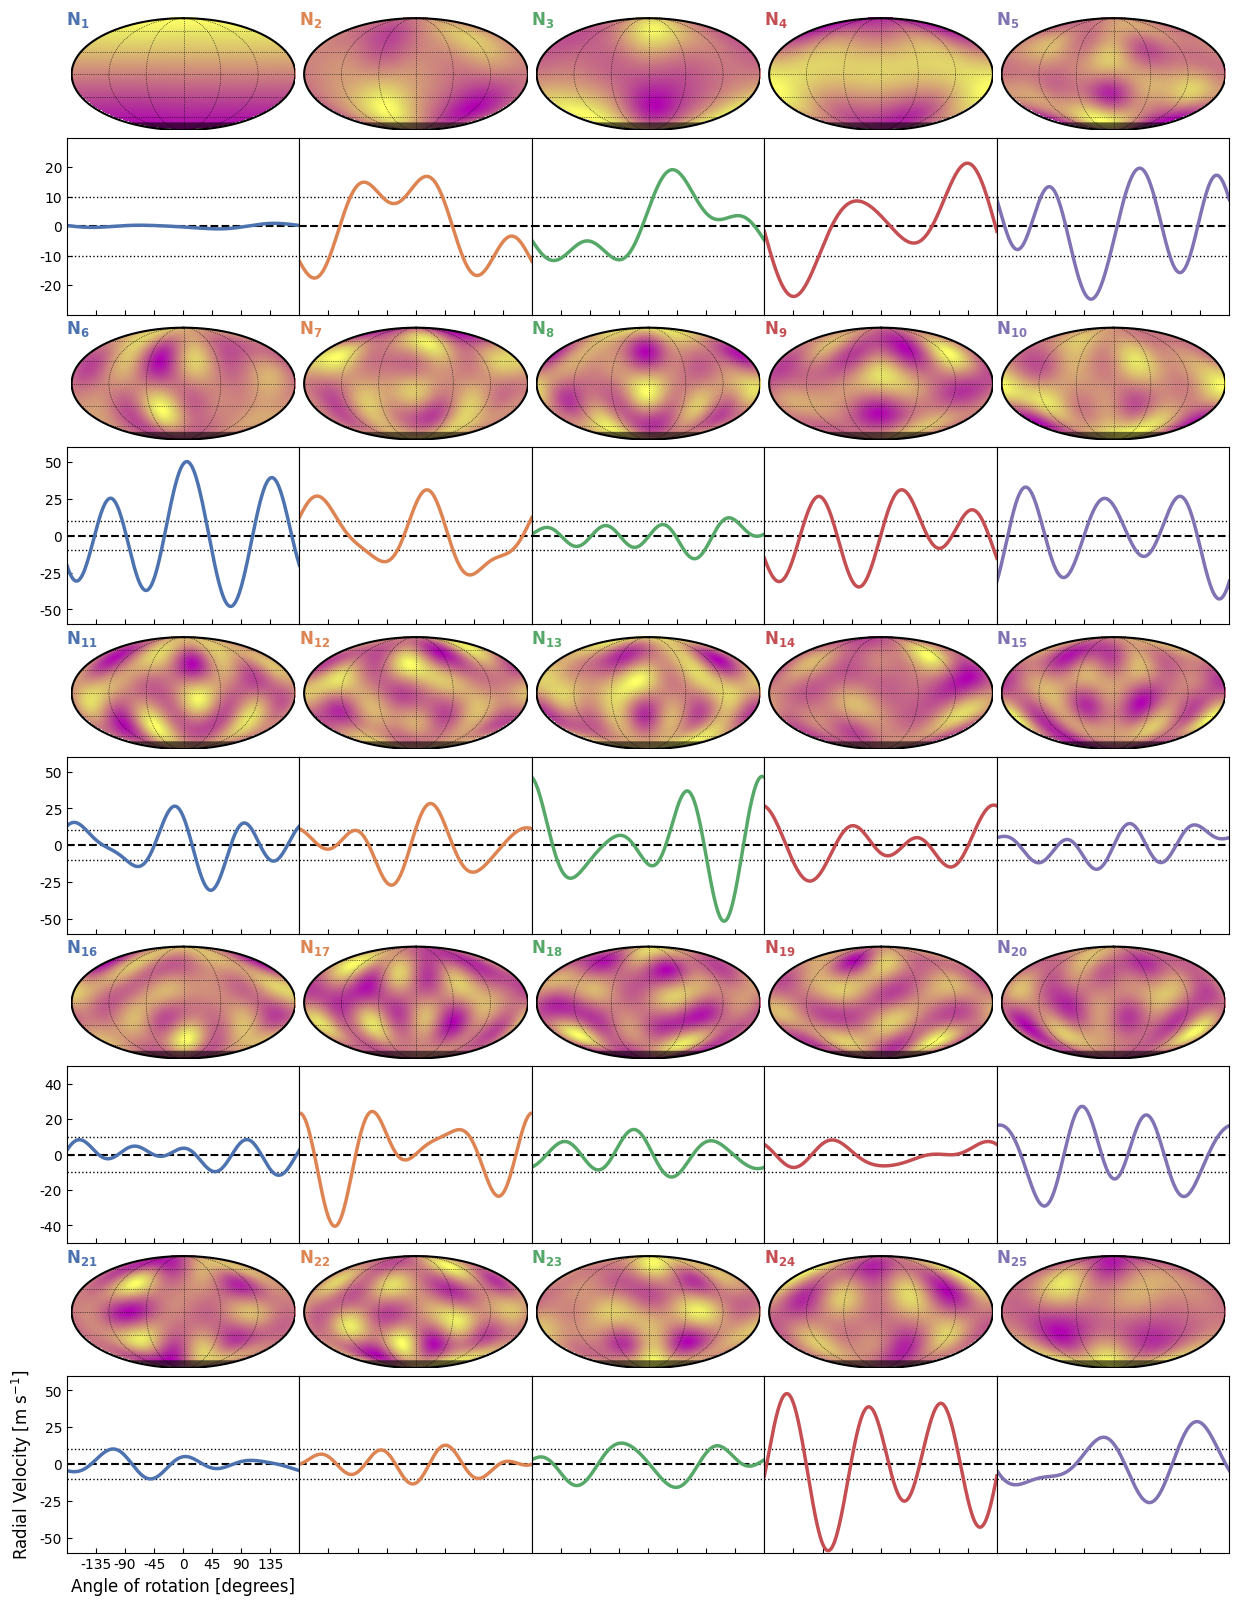

In [10]:
def rv_curves_two(star, y_coeffs, amps, ratio, theta = np.linspace(-180, 180, 361), fname = None,
                 transparent=False, labels=True, title = None, border=True, ticks=True, 
                 fontsize=16, colors=[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725), 
                                    (0.8666666666666667, 0.5176470588235295, 0.3215686274509804), 
                                    (0.3333333333333333, 0.6588235294117647, 0.40784313725490196), 
                                    (0.7686274509803922, 0.3058823529411765, 0.3215686274509804), 
                                    (0.5058823529411764, 0.4470588235294118, 0.7019607843137254), ], 
                 guidelines=True, cbar_center=None,
                 centerline=True, cline_color="k", dpi=300):
    

    fig = plt.figure(figsize=(15, 20))
    gs = gridspec.GridSpec(10, 5, figure=fig,height_ratios=[1,1.5]*5)

    # if cbar_center is None:
    #     gs = gridspec.GridSpec(10, 5, figure=fig,height_ratios=[1,1.5]*5)
    # else:
        # gs = gridspec.GridSpec(10, 6, figure=fig,height_ratios=[1,1.5]*5, width_ratios=[1]*5 + [0.05])

    image = star.map.render(theta=0,projection="moll",rv=False).eval()

    dx = 360.0 / image.shape[1] 
    dy = 180.0 / image.shape[0]

    if fname:
        extent = np.array([
            -180 - dx/2,  # Left
            180 - dx/2,       # Right
            -90 - dy/2,   # Bottom
            90 - dy/2         # Top
        ])
    else:
        extent = np.array([
            -180 - dx,  # Left
            180,      # Right
            -90 - dy,   # Bottom
            90 - dy/8         # Top
        ])

    k = 0

    axes_list = []
    for i in range(5):

        r = (i*2) + 1

        # if cbar_center is None:
        #     c_ax = fig.add_subplot(gs[r, :])
        # else:
        #     c_ax = fig.add_subplot(gs[r, :-1])

        max_rv = float("-inf")
        min_rv = float("inf")

        for j in range(5):

            c_ax = fig.add_subplot(gs[r, j])

            star.map[:,:] = y_coeffs[k]

            star.map.amp = amps[k]

            rv_val = star.map.rv(theta=theta).eval()

            c_ax.plot(theta,rv_val,color=colors[j],zorder=2,lw=2.5)

            if centerline:
                c_ax.axhline(y=0,color=cline_color,linestyle="--",zorder=1,linewidth=1.5)

            if guidelines:
                c_ax.axhline(y=10,color=cline_color,linestyle=":",zorder=1,linewidth=1)
                c_ax.axhline(y=-10,color=cline_color,linestyle=":",zorder=1,linewidth=1)

            if np.max(rv_val) > max_rv:
                 max_rv = np.max(rv_val)
            if np.min(rv_val) < min_rv:
                 min_rv = np.min(rv_val)

            if i == 4 and j == 0 and labels:
                c_ax.set_xlabel("Angle of rotation [degrees]", fontsize=fontsize*.75)

            if i == 4 and j == 0 and labels:
                c_ax.set_ylabel(f"Radial Velocity [m s$^{{-1}}$]", fontsize=fontsize*.75)

            k += 1


        if not ticks:
            for j in range(5):
                l_ax = plt.subplot(gs[r, j])
                l_ax.set_xticklabels([])
                l_ax.set_yticklabels([])
                l_ax.tick_params(left=False, bottom=False)

        else:
            for j in range(5):

                l_ax = plt.subplot(gs[r, j])

                l_ax.tick_params(direction="in")

                l_ax.set_xticks([-135,-90,-45,0,45,90,135])
                l_ax.set_xticklabels([-135,-90,-45,0,45,90,135])
                
                if j != 0 or i != 4:
                    l_ax.set_xticklabels([])

                l_ax.set_xlim(-180,180)

                amp = np.max([max_rv,np.abs(min_rv)])


                bounds = (amp // 10) * 10

                buffer = 10

                y_tick_values = [-bounds, (-bounds) / 2, 0, (bounds) / 2, bounds] 
                l_ax.set_yticks(y_tick_values)
                l_ax.set_yticklabels([f"{val:.0f}" for val in y_tick_values])
                l_ax.set_ylim(0 - bounds - buffer, 0 + bounds + buffer)

                if j != 0:
                    l_ax.set_yticklabels([])
                    l_ax.tick_params(left=False)



    # if cbar_center is not None:
    #     norm = mpl.colors.TwoSlopeNorm(vmin=cbar_center * .42, vmax=cbar_center * 1.35,vcenter=cbar_center)
    #     # print(cbar_center * .42, cbar_center, cbar_center * 1.35)
    # else:
    #     norm = None

    norm = None

    k = 0
    for i in range(5):

        for j in range(5):

            ax = fig.add_subplot(gs[i*2, j])
            star.map[:,:] = y_coeffs[k]  

            star.map.amp = amps[k]  

            star.map.amp /= ratio
            current_map = star.map.render(theta=0, projection="moll", rv=False).eval()
            star.map.amp *= ratio

            # print(f"{k}: {np.nanmin(current_map),np.nanmax(current_map)}")

            ax.text(x=-0.02, y=.9, s=f"$\\mathbf{{N_{{{k+1}}}}}$", fontsize=fontsize*.75, transform=ax.transAxes,color=colors[j])
           
            im = ax.imshow(current_map,
                    origin="lower",
                    cmap=cm.buda.resampled(512),
                    extent=extent,
                    norm = norm) 

            lats = lat_lon_lines.get_moll_latitude_lines(dlat=30,unseen_deg=None)
            latlines = [None for n in lats]

            for n, l in enumerate(lats):

                (latlines[n],) = ax.plot(
                    l[0], l[1], "k:", lw=0.5, alpha=1, zorder=0
                )

            lons = lat_lon_lines.get_moll_longitude_lines(dlon=60)
            lonlines = [None for n in lons]
            for n, l in enumerate(lons):

                if (n == 0 or n == len(lons) - 1):
                    (lonlines[n],) = plt.plot(
                        l[0], l[1], "k-", lw=1.5, alpha=1, zorder=1
                    )

                else:
                    (lonlines[n],) = ax.plot(
                        l[0], l[1], "k:", lw=0.5, alpha=1, zorder=0
                    )              

            unseen_degree = star.map.inc.eval()

            if unseen_degree > 90:
                fill_direction = -1
                unseen_degree = 180 - unseen_degree
            else:
                fill_direction = 1
                unseen_degree *= -1


            lats = lat_lon_lines.get_moll_latitude_lines(dlat=0, unseen_deg=unseen_degree)

            x_vals = np.array(lats[0][0])
            fill_val = np.array(lats[0][1])

            lat_xs = x_vals[~np.isnan(fill_val)]  

            lons = lat_lon_lines.get_moll_longitude_lines(dlon=360)
            lonlines = [None for n in lons]

            lon_xs = np.array([])
            lon_ys = np.array([])

            for n, l in enumerate(lons):
                x_is = np.argsort(l[0])

                lon_xs = np.append(lon_xs,l[0][x_is])
                lon_ys = np.append(lon_ys,l[1][x_is])

            x_mask = (lon_xs > np.min(lat_xs)) & (lon_xs < np.max(lat_xs))

            y_mask = (lon_ys < np.nanmedian(fill_val))

            xs = lon_xs[x_mask & y_mask]

            ys = lon_ys[x_mask & y_mask]

            ax.fill_between(xs, ys * fill_direction, np.nanmedian(fill_val), 
                    color="k", alpha = .6, edgecolor='none')

            ax.set_xticklabels([])
            ax.set_yticklabels([])
            ax.tick_params(left=False, bottom=False)
            
            ax.set_frame_on(False)
                       

            k += 1



    if title:
        fig.sup_title(title,fontsize=fontsize*1.5)

    if not border:
        plt.gca().set_frame_on(False)

    plt.subplots_adjust(wspace=0)

    # plt.tight_layout()
    fig.subplots_adjust(hspace=.05)
    fig.subplots_adjust(wspace=0)

    # if cbar_center is not None:

    #     cbar_ax = fig.add_subplot(gs[:, 5])

    #     cbar = fig.colorbar(im, cax=cbar_ax, shrink=0.95, aspect = 40, pad = .03)
    #     cbar.ax.tick_params(labelsize=fontsize * .60, rotation = 0)

    #     cbar.set_label(f"Flux [{units}]", size=fontsize * .75, rotation = 270, labelpad = 15)
        
    #     cbar.ax.yaxis.get_offset_text().set_visible(False)
    
    if fname:
        plt.savefig(fname, dpi = dpi, transparent=transparent,bbox_inches="tight")
    else:
        plt.show()
    plt.close()


rv_curves_two(star, scaled_eigeny, amps, ratio_no_limb, fname="rv_curves_outputs/rv_curves_two.png")
rv_curves_two(star, scaled_eigeny, amps, ratio_no_limb, cbar_center=None)